<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>

#### Import the required libraries we need for the lab.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL

In [ ]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [3]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment

## Task 1: Familiarize Yourself with the Dataset

### Question 1: Display the first 5 rows of the dataset

In [4]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


### Question 2: Display the data type of each column

In [5]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

### Question 3: Check for missing values in each column

In [6]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

### Question 4: Check for duplicate rows

In [7]:
boston_df.duplicated().sum()

np.int64(0)

### Question 5: Compute the correlation matrix

In [8]:
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


## Task 2: Descriptive Statistics and Visualizations

### Question 6: Descriptive statistics of the dataset

In [9]:
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### Scatter plot of NOX vs. INDUS

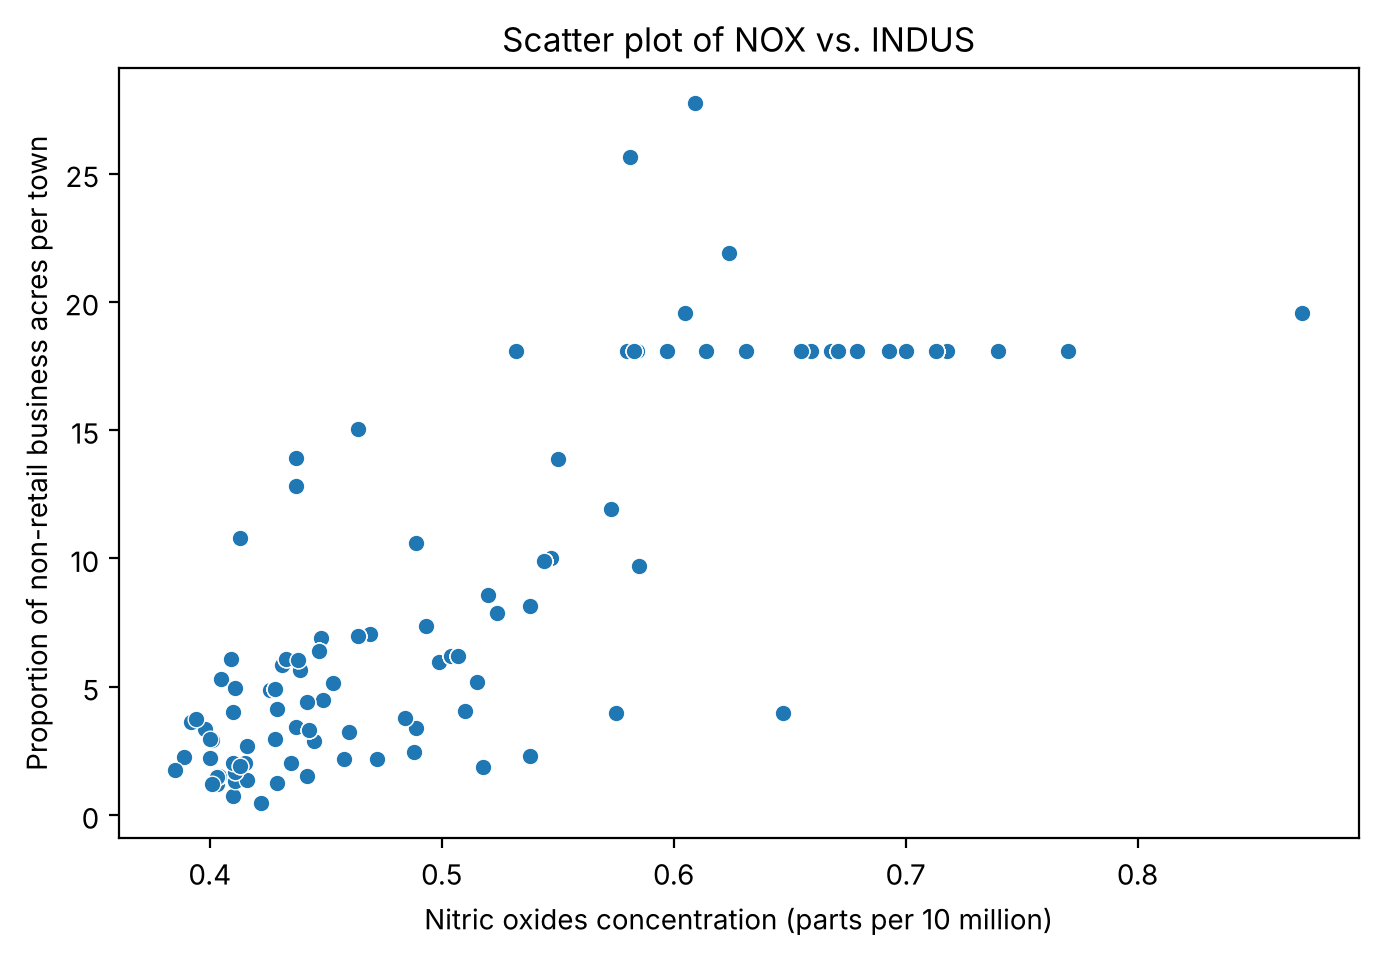

In [10]:
pyplot.figure(figsize=(8, 5))
sns.scatterplot(x="NOX", y="INDUS", data=boston_df)
pyplot.title("Scatter plot of NOX vs. INDUS")
pyplot.xlabel("Nitric oxides concentration (parts per 10 million)")
pyplot.ylabel("Proportion of non-retail business acres per town")
pyplot.show()

**Interpretation:** NOX and INDUS have a positive relationship. Towns with a higher proportion of non-retail business acres tend to have a higher nitric oxide concentration. The relationship is not perfectly linear, and many towns share the same INDUS value of about 18.

### Histogram of the pupil-to-teacher ratio (PTRATIO)

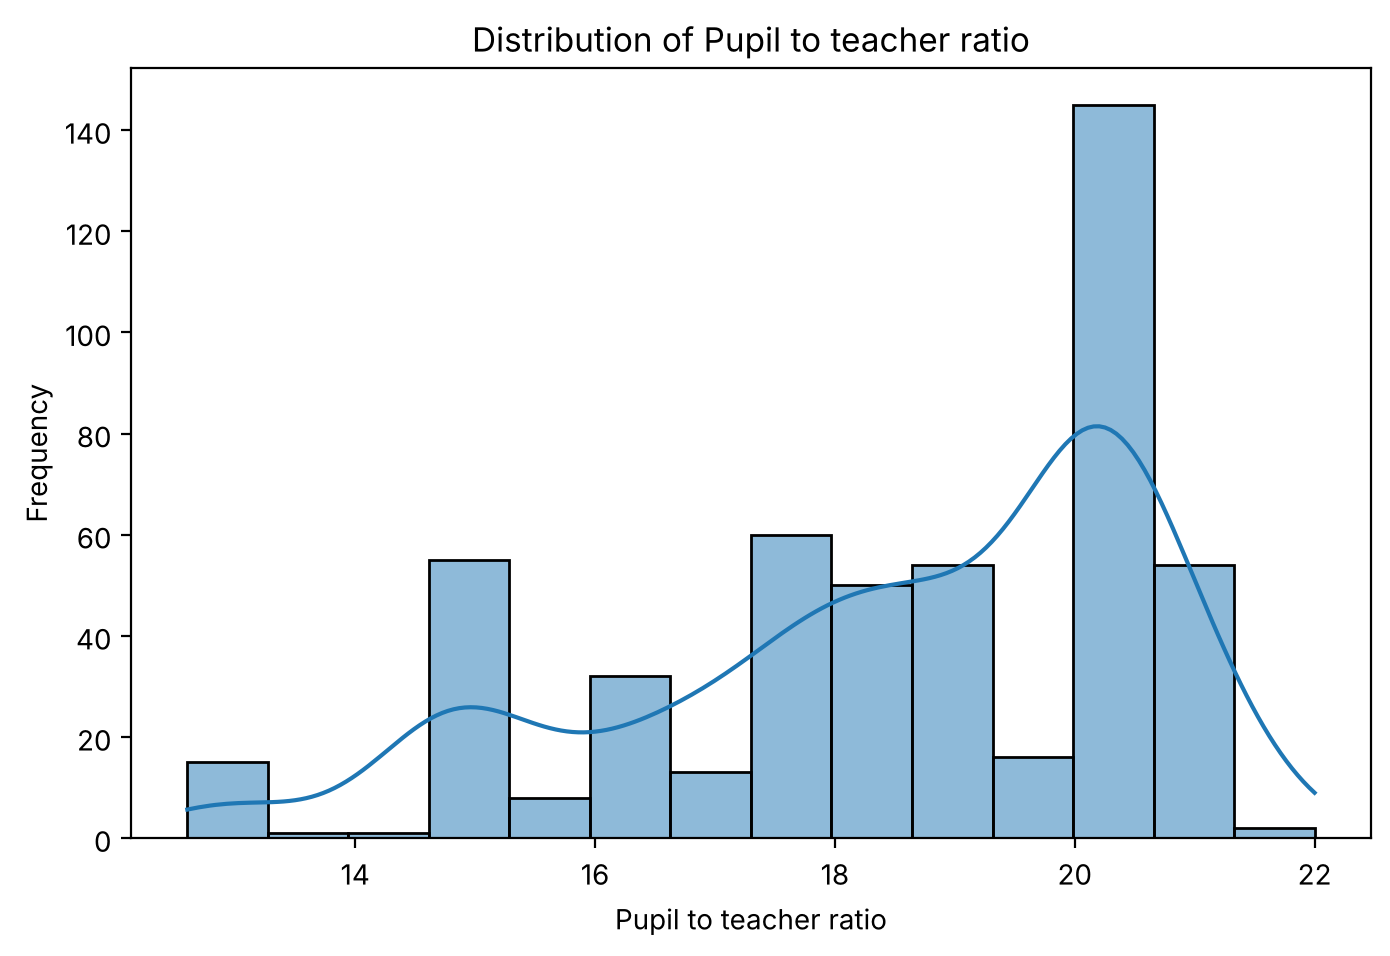

In [11]:
pyplot.figure(figsize=(8, 5))
sns.histplot(boston_df["PTRATIO"], kde=True)
pyplot.title("Distribution of Pupil to teacher ratio")
pyplot.xlabel("Pupil to teacher ratio")
pyplot.ylabel("Frequency")
pyplot.show()

**Interpretation:** The distribution of PTRATIO is skewed to the left. The highest peak is at about 20 to 21, and fewer towns have a ratio below 15 (58 towns) than above 20 (201 towns).

### Boxplot of the median value of owner-occupied homes (MEDV)

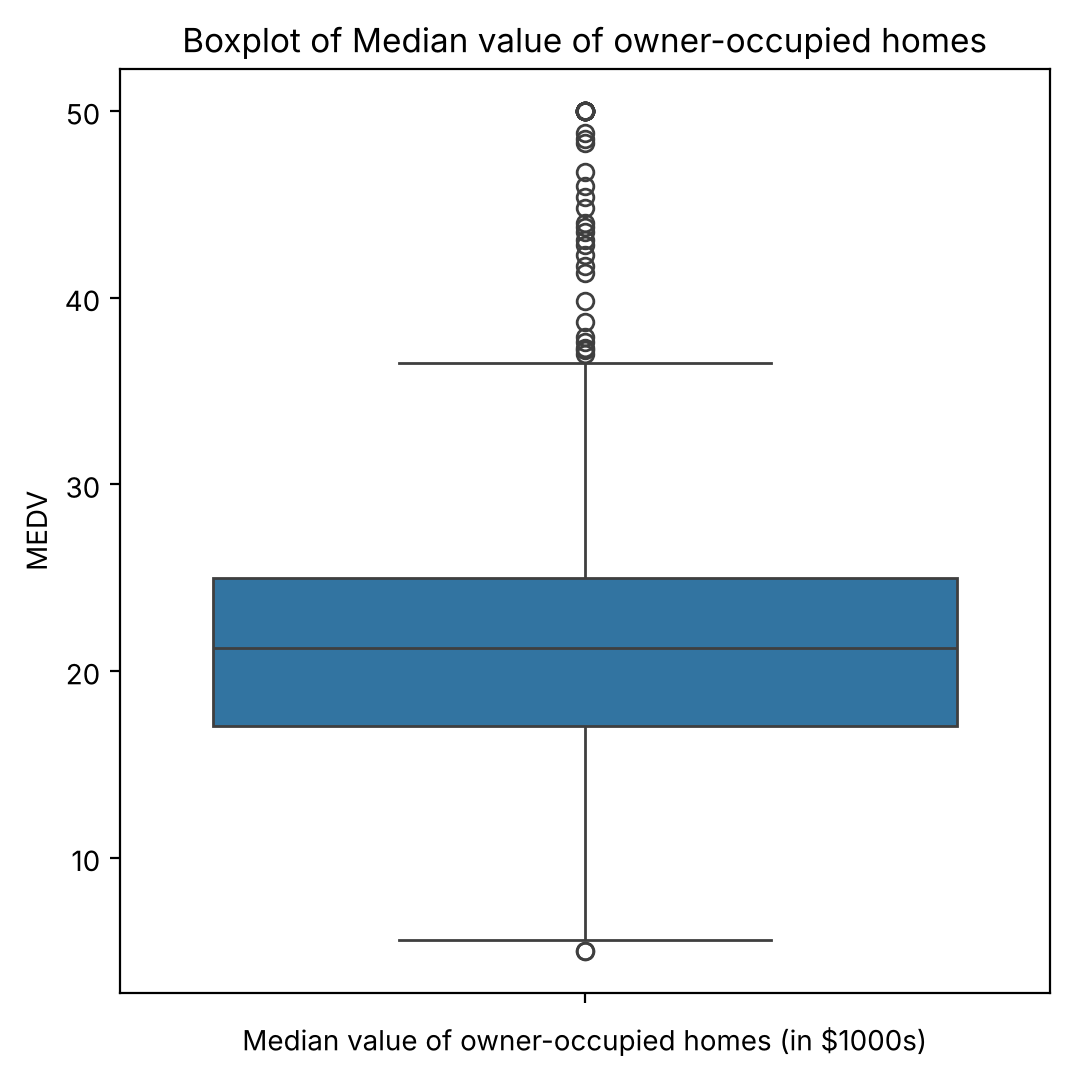

In [12]:
pyplot.figure(figsize=(6, 6))
sns.boxplot(y="MEDV", data=boston_df)
pyplot.title("Boxplot of Median value of owner-occupied homes")
pyplot.ylabel("MEDV")
pyplot.xlabel("Median value of owner-occupied homes (in $1000s)")
pyplot.show()

**Interpretation:** The median of MEDV is about 21.2 (in $1000s) and the middle 50% of the values lie between about 17.0 and 25.0. There are several outliers with very high house prices.

### Boxplot of MEDV by age group

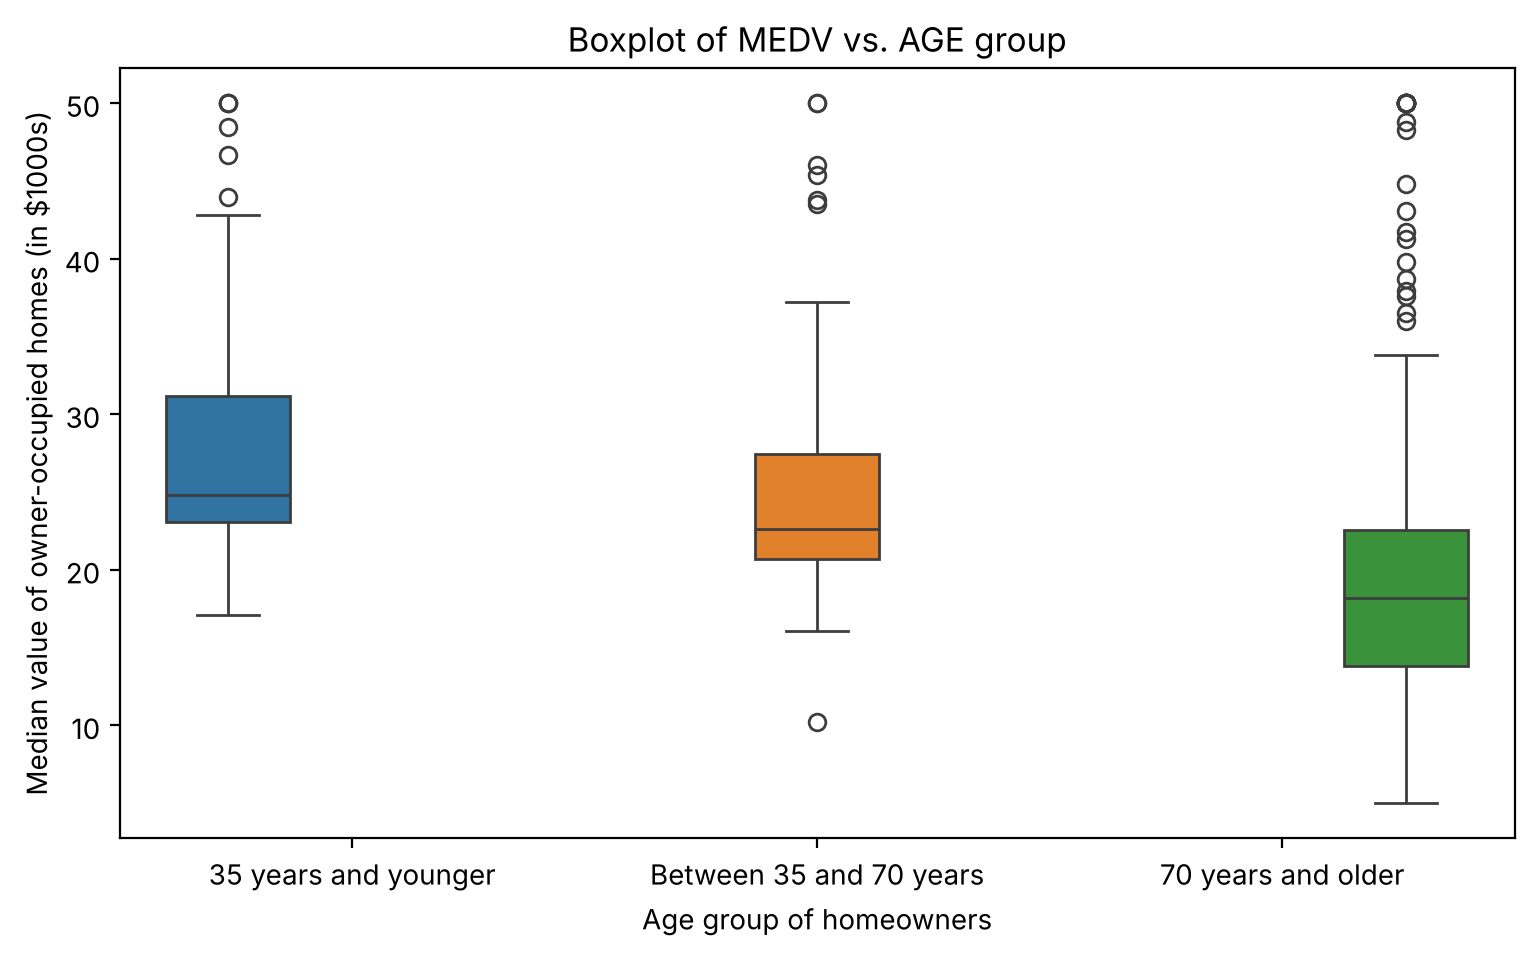

In [13]:
boston_df["age_group"] = pd.cut(boston_df["AGE"], bins=[0, 35, 70, 100],
                                labels=["35 years and younger", "Between 35 and 70 years", "70 years and older"])
pyplot.figure(figsize=(9, 5))
sns.boxplot(x="age_group", y="MEDV", data=boston_df, hue="age_group", legend=False)
pyplot.title("Boxplot of MEDV vs. AGE group")
pyplot.xlabel("Age group of homeowners")
pyplot.ylabel("Median value of owner-occupied homes (in $1000s)")
pyplot.show()

**Interpretation:** The median value of homes decreases as the age group increases: about 24.8 for the youngest group, 22.6 for the middle group and 18.2 for the oldest group. The oldest group has the lowest median and the most high outliers. All three groups have outliers.

### Bar plot of the Charles River variable (CHAS)

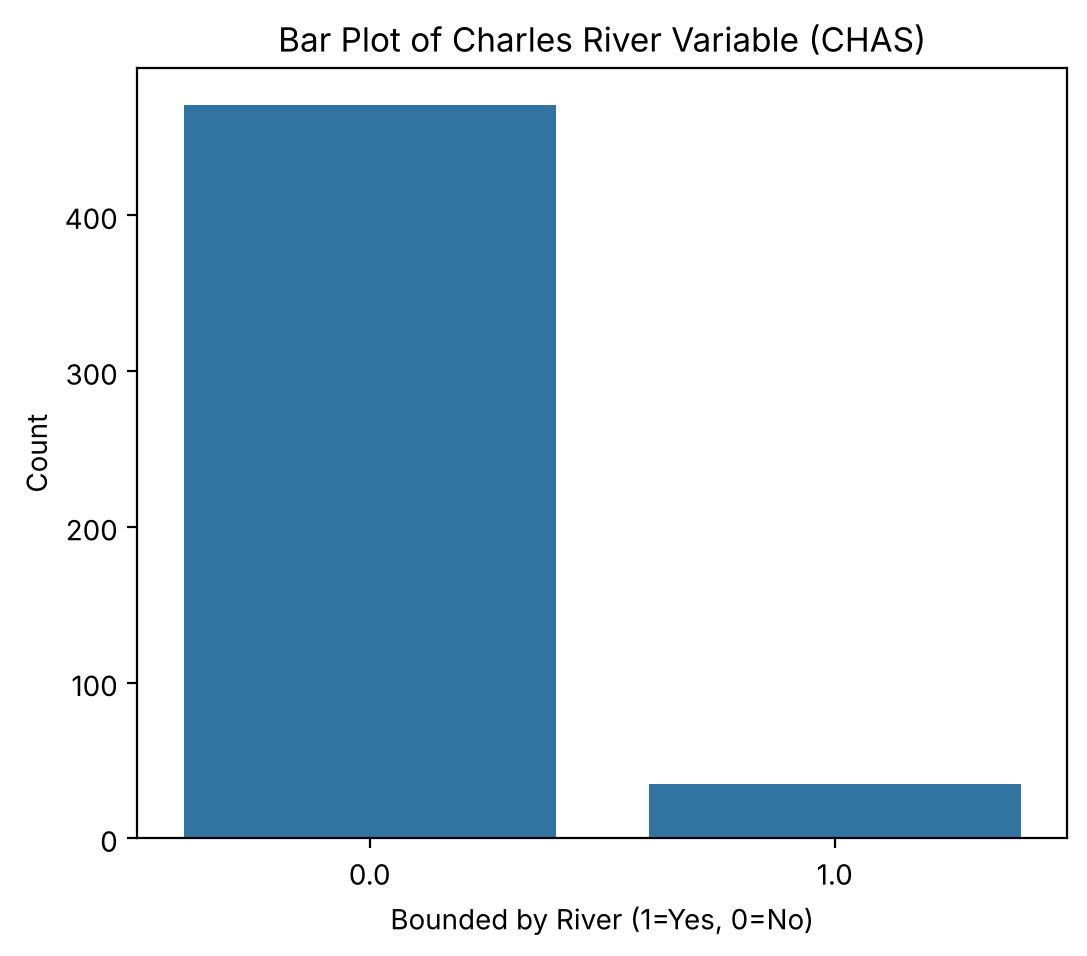

In [14]:
pyplot.figure(figsize=(6, 5))
sns.countplot(x="CHAS", data=boston_df)
pyplot.title("Bar Plot of Charles River Variable (CHAS)")
pyplot.xlabel("Bounded by River (1=Yes, 0=No)")
pyplot.ylabel("Count")
pyplot.show()

**Interpretation:** Only 35 of the 506 houses are bounded by the Charles River, while 471 are not. Most houses are not located next to the river.

## Task 3: Hypothesis Testing and Regression

The significance level used in all tests is $\alpha = 0.05$.

### Question 12: Levene's test for equality of variances (CHAS)

- $H_0$: the variances of MEDV are equal for houses bounded and not bounded by the river
- $H_1$: the variances of MEDV are not equal

In [15]:
alpha = 0.05
bounded = boston_df[boston_df["CHAS"] == 1]["MEDV"]
not_bounded = boston_df[boston_df["CHAS"] == 0]["MEDV"]

lev_stat, lev_p = scipy.stats.levene(bounded, not_bounded, center="mean")
print("Levene statistic:", lev_stat)
print("p-value:", lev_p)
if lev_p < alpha:
    print("Reject H0: the variances are not equal.")
else:
    print("Fail to reject H0: the variances are equal.")

Levene statistic: 8.75190489604598
p-value: 0.0032381193676394252
Reject H0: the variances are not equal.


**Conclusion:** The p-value (about 0.0032) is below 0.05, so H0 is rejected. The variances of MEDV are not equal between houses bounded and not bounded by the river, so the t-test below uses unequal variances.

### Question 13: T-test for the difference in mean MEDV (CHAS)

- $H_0$: the mean MEDV is equal for houses bounded and not bounded by the river
- $H_1$: the mean MEDV is different

In [16]:
t_stat, t_p = scipy.stats.ttest_ind(bounded, not_bounded, equal_var=(lev_p >= alpha))
print("t-statistic:", t_stat)
print("p-value:", t_p)
if t_p < alpha:
    print("Reject H0: there is a significant difference in the mean MEDV.")
else:
    print("Fail to reject H0: there is no significant difference in the mean MEDV.")

t-statistic: 3.113291312794837
p-value: 0.003567170098137519
Reject H0: there is a significant difference in the mean MEDV.


**Conclusion:** The p-value (about 0.0036) is below 0.05, so H0 is rejected. There is a significant difference in the mean MEDV, and houses bounded by the Charles River have the higher mean (the t-statistic is positive).

### Question 14: ANOVA for the difference in MEDV across the three age groups

- $H_0$: the mean MEDV is equal across all three age groups
- $H_1$: at least one age group has a different mean MEDV

In [17]:
group1 = boston_df[boston_df["age_group"] == "35 years and younger"]["MEDV"]
group2 = boston_df[boston_df["age_group"] == "Between 35 and 70 years"]["MEDV"]
group3 = boston_df[boston_df["age_group"] == "70 years and older"]["MEDV"]

f_stat, f_p = scipy.stats.f_oneway(group1, group2, group3)
print("F-statistic:", f_stat)
print("p-value:", f_p)
if f_p < alpha:
    print("Reject H0: at least one age group has a different mean MEDV.")
else:
    print("Fail to reject H0: the mean MEDV is the same across the age groups.")

F-statistic: 36.40764999196599
p-value: 1.7105011022701404e-15
Reject H0: at least one age group has a different mean MEDV.


**Conclusion:** The F-statistic is about 36.4 and the p-value (about 1.7e-15) is far below 0.05, so H0 is rejected. At least one age group has a different mean MEDV, which agrees with the boxplot.

### Question 15: Pearson correlation between NOX and INDUS

- $H_0$: NOX and INDUS are not correlated
- $H_1$: NOX and INDUS are correlated

In [18]:
r, r_p = scipy.stats.pearsonr(boston_df["NOX"], boston_df["INDUS"])
print("Pearson correlation coefficient (r):", r)
print("p-value:", r_p)
if r_p < alpha:
    print("Reject H0: NOX and INDUS are significantly correlated.")
else:
    print("Fail to reject H0: no significant correlation between NOX and INDUS.")

Pearson correlation coefficient (r): 0.7636514469209154
p-value: 7.913361061239639e-98
Reject H0: NOX and INDUS are significantly correlated.


**Conclusion:** The correlation coefficient is about 0.76 and the p-value is far below 0.05, so H0 is rejected. NOX and INDUS have a strong, significant positive linear correlation.

### Question 16: Simple linear regression of MEDV on DIS

- $H_0$: the slope of DIS is 0 (DIS has no effect on MEDV)
- $H_1$: the slope of DIS is not 0

In [19]:
X = sm.add_constant(boston_df["DIS"])
y = boston_df["MEDV"]
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        17:15:46   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

In [20]:
slope = model.params["DIS"]
slope_p = model.pvalues["DIS"]
print("Slope of DIS:", slope)
print("p-value of the slope:", slope_p)
print("R-squared:", model.rsquared)
if slope_p < alpha:
    print("Reject H0: DIS has a significant effect on MEDV.")
else:
    print("Fail to reject H0: DIS has no significant effect on MEDV.")

Slope of DIS: 1.0916130158411075
p-value of the slope: 1.206611727337178e-08
R-squared: 0.062464372121782574
Reject H0: DIS has a significant effect on MEDV.


**Conclusion:** The slope of DIS is about 1.09 and its p-value (about 1.2e-8) is below 0.05, so H0 is rejected. Each additional unit of DIS is associated with an increase of about 1.09 (about $1,090) in MEDV. R-squared is only about 0.06, so DIS explains a small part of the variation in MEDV.